## Task 1 Baseline Discrete Local Search (Hill‑Climber)
### Student: Beverly, Echo
### Student ID: 202316801316,202316801317

### Common utility functions
Below are shared helper functions reused by all group members:
1. `calculate_total_resource()`: compute total hardware resource consumption for a binary solution
2. `is_feasible()`: check whether a solution respects all hardware capacity bounds
3. `fitness()`: objective function with **penalty‑based constraint handling**.
If solution violates resource constraints, heavy penalty is subtracted from utility value to discourage infeasible solutions.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ========= Shared group functions (consistent with team‑member interface) =========
def load_instance(file_path):
    
    with open(file_path, 'r') as f:
        tokens = f.read().split()

    if not tokens:
        raise ValueError(f"Dataset file at '{file_path}' is empty or invalid.")

    n = int(tokens[0])
    m = int(tokens[1])
    idx = 2

    v = np.array([float(x) for x in tokens[idx: idx + n]])
    idx += n

    W = np.zeros((m, n))
    for i in range(m):
        W[i, :] = [float(x) for x in tokens[idx: idx + n]]
        idx += n

    b = np.array([float(x) for x in tokens[idx: idx + m]])
    return n, m, v, W, b

def is_feasible(sol, W, b):
    "Check if the solution is feasible: sol is a 0/1 array"
    cons = W @ sol
    return np.all(cons <= b + 1e-9)

def evaluate_fitness(sol, v, W, b):
    "Basic fitness: Feasible solutions = total value; Infeasible = 0"
    if is_feasible(sol, W, b):
        return float(v @ sol)
    else:
        return 0.0


# ========== Variant B Core: Repair Recovery Strategy  ==========
def repair_solution(sol, W, b, v):

    sol = sol.copy().astype(int)
    n = len(sol)
    # value density
    density = np.zeros(n)
    mask = sol == 1
    density[mask] = v[mask] / (W[:,mask].sum(axis=0) + 1e-9)
    # Retrieve the index of the currently selected item, sort them in ascending order of density
    selected_idx = np.where(sol == 1)[0]
    selected_idx = selected_idx[np.argsort(density[selected_idx])]

    for idx in selected_idx:
        if is_feasible(sol, W, b):
            break
        sol[idx] = 0
    return sol


# ==================== Variant‑A Penalty‑based constraint handling (Part‑1 Hill‑Climber) ====================
def fitness_penalty(sol, v, W, b, penalty_weight=10000):
    
    total_val = np.sum(v * sol)
    if is_feasible(sol, W, b):
        return total_val
    overshoot = np.maximum((W @ sol) - b, 0.0)
    return total_val - penalty_weight * np.sum(overshoot)

### 1.1 Hill‑Climber algorithm design
1. **Solution representation**: Binary numpy vector `sol` of length n. $sol_j=1$ means deploy model $j$; $sol_j=0$ means skip model $j$.
2. **Neighbourhood / Mutation operator**: Single‑bit flip. In each iteration pick one random index and toggle value $0 \leftrightarrow 1$ to generate neighbour candidate solution.
3. **Acceptance rule (greedy hill‑climbing)**: Only accept neighbour candidate if it achieves higher penalised fitness value.
4. **Constraint‑handling**: Use **Variant‑A penalty‑function (`fitness_penalty`)**. Infeasible solutions receive heavy fitness penalty, but solution vector will not be modified.
5. **Stopping condition**: fixed maximum iteration search budget.

Known limitation: Greedy hill‑climber is prone to being trapped in local optima and lacks global exploration capacity. It works as a baseline solver for small‑scale instance n=28, but cannot handle high‑dimensional n=90 challenge problem.

In [4]:
def hill_climber(n, v, W, b, max_iter=1500, seed=42):
    rng = np.random.default_rng(seed)
    # generate random initial binary solution
    current_sol = rng.integers(0, 2, size=n)
    current_fit = fitness_penalty(current_sol, v, W, b)

    best_sol = current_sol.copy()
    best_fit = current_fit
    convergence_history = []

    for _ in range(max_iter):
        convergence_history.append(best_fit)
        # single‑bit flip neighbour operator
        neighbour = current_sol.copy()
        flip_pos = rng.integers(0, n)
        neighbour[flip_pos] = 1 - neighbour[flip_pos]

        neighbour_fit = fitness_penalty(neighbour, v, W, b)
        # greedy acceptance: accept only better fitness
        if neighbour_fit > current_fit:
            current_sol = neighbour
            current_fit = neighbour_fit
            if current_fit > best_fit:
                best_fit = current_fit
                best_sol = current_sol.copy()
    return best_sol, best_fit, convergence_history

### 1.2 Experimental setup
- Dataset file: `multi_resource_n28_m2.txt` ($n=28$, $m=2$)
- Number of independent repeated runs: 10
- Max iterations for each single run: 1500
- Reproducibility: Each independent run uses distinct fixed random seed.

We collect final best fitness value from every run for statistical summary, and store full convergence history to plot convergence curve.

==== Hill‑Climber Results | Instance n=28 m=2 ====
Independent runs: 10
Iteration budget per run: 1500
Maximum fitness: 95205.00
Minimum fitness: 39012.00
Mean fitness:    73649.90
Std deviation:  16970.18


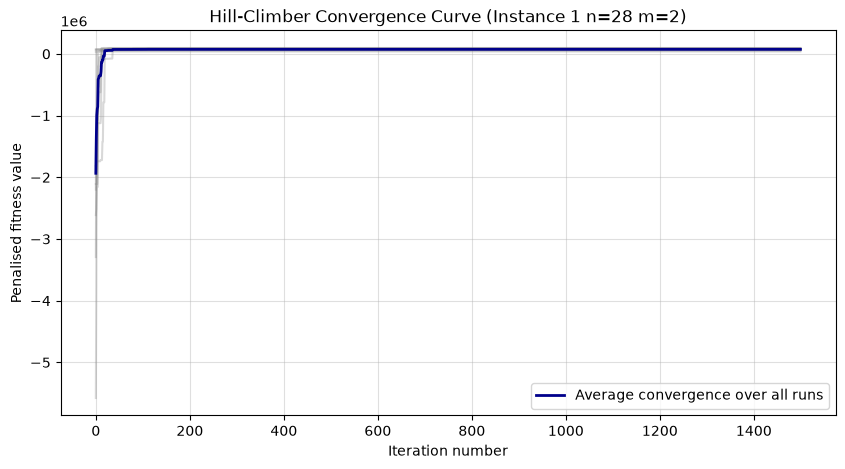

In [5]:
# load dataset
n, m, v, W, b = load_instance(r"D:/大四上/AI/数据/multi_resource_n28_m2 .txt")

num_runs = 10
max_iter = 1500

all_best_fitness = []
all_convergence_histories = []

for run_id in range(num_runs):
    best_s, best_fit, hist = hill_climber(n, v, W, b, max_iter=max_iter, seed=run_id)
    all_best_fitness.append(best_fit)
    all_convergence_histories.append(hist)

# print statistical summary
print("==== Hill‑Climber Results | Instance n=28 m=2 ====")
print(f"Independent runs: {num_runs}")
print(f"Iteration budget per run: {max_iter}")
print(f"Maximum fitness: {np.max(all_best_fitness):.2f}")
print(f"Minimum fitness: {np.min(all_best_fitness):.2f}")
print(f"Mean fitness:    {np.mean(all_best_fitness):.2f}")
print(f"Std deviation:  {np.std(all_best_fitness):.2f}")

# plot convergence graph
plt.figure(figsize=(10,5), dpi=100)
for h in all_convergence_histories:
    plt.plot(h, c="gray", alpha=0.3)

mean_curve = np.mean(np.array(all_convergence_histories), axis=0)
plt.plot(mean_curve, c="darkblue", lw=2, label="Average convergence over all runs")

plt.title("Hill‑Climber Convergence Curve (Instance 1 n=28 m=2)")
plt.xlabel("Iteration number")
plt.ylabel("Penalised fitness value")
plt.legend()
plt.grid(alpha=0.4)
plt.show()

### 1.3 Result analysis & discussion
From printed numerical statistics and convergence plot:

1. **Convergence behaviour**: The penalised fitness starts from negative values (infeasible initial solutions) and rises extremely rapidly within the first few iterations. Improvement quickly plateaus, and the algorithm converges to a local optimum for the remaining search budget.

2. **Performance variance across runs**: There is a large spread of fitness values across independent runs. The results show a standard deviation of 16970.18, with best fitness 95205.00 and worst 39012.00. Final solution quality heavily depends on the random starting solution, which is a well‑known drawback of greedy local‑search hill‑climbing.

3. **Constraint‑handling observation (Variant‑A penalty function)**: Penalty fitness discourages infeasible configurations. However, the penalty strategy will not modify invalid candidate solutions; search evaluations may be wasted exploring infeasible regions of the solution space.

4. **Baseline conclusion**: Hill‑climber can deliver acceptable results for the small‑scale $n=28$ instance. Nevertheless, it lacks global search ability and struggles to consistently find high‑quality solutions, as shown by the large standard deviation. This motivates the population‑based metaheuristic algorithm in Part 2.

For Part‑3 empirical study, Variant‑A penalty function will be compared against Variant‑B repair‑based constraint‑handling strategy, using the identical population‑based metaheuristic algorithm on a larger challeng instance.
 instance.

# Task 3 Comparative Experiment & Statistical Test

# Multi-Resource Knapsack: Variant A (Penalty) vs Variant B (Repair)

## 1. Importing libraries and setting up plotting

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
import random
import time
import os

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

## 2. Public base: Data loading + Feasibility check

In [2]:
def load_workload_instance(file_path):
    """
    Official lecturer‑provided dataset loader
    Return n, m, utilities, demands, capacities
    """
    with open(file_path, 'r') as f:
        tokens = f.read().split()

    if not tokens:
        raise ValueError(f"Dataset file at '{file_path}' is empty or invalid.")

    n = int(tokens[0])
    m = int(tokens[1])
    idx = 2

    utilities = np.array([float(x) for x in tokens[idx: idx + n]])
    idx += n

    demands = np.zeros((m, n))
    for i in range(m):
        demands[i, :] = [float(x) for x in tokens[idx: idx + n]]
        idx += n

    capacities = np.array([float(x) for x in tokens[idx: idx + m]])
    return n, m, utilities, demands, capacities


def is_feasible(solution, demands, capacities):
    """
    Check binary solution satisfies resource constraints.
    Add epsilon 1e‑9 for floating‑point numerical tolerance.
    """
    res_used = demands @ solution
    return np.all(res_used <= capacities + 1e-9)


# ---------------- Variant A : Penalty‑based constraint handling (Part 1) ----------------
def fitness_penalty(solution, utilities, demands, capacities, penalty_weight=10000):
    """
    Variant‑A Penalty function
    Feasible → raw total utility
    Infeasible → subtract penalty proportional to resource overshoot
    The input solution vector is NOT modified.
    """
    total_u = np.sum(utilities * solution)
    if is_feasible(solution, demands, capacities):
        return total_u
    overshoot = np.maximum((demands @ solution) - capacities, 0.0)
    return total_u - penalty_weight * np.sum(overshoot)


# ---------------- Variant B : Repair‑based constraint handling (Part2 & Part3) ----------------
def repair_solution(sol, demands, capacities, utilities):
    """
    Variant‑B Repair strategy:
    For infeasible solution, remove selected models ordered by ascending utility‑density (remove lowest‑value‑per‑resource first), until feasible.
    Return repaired feasible binary solution copy.
    """
    sol = sol.copy().astype(int)
    n = len(sol)
    density = np.zeros(n)
    mask = sol == 1
    density[mask] = utilities[mask] / (demands[:, mask].sum(axis=0) + 1e-9)

    selected_idx = np.where(sol == 1)[0]
    selected_idx = selected_idx[np.argsort(density[selected_idx])]

    for idx in selected_idx:
        if is_feasible(sol, demands, capacities):
            break
        sol[idx] = 0
    return sol
    
def fitness_repair(sol, utilities, demands, capacities):
    """
    Fitness for Variant-B: repair first, then return (utility, repaired_solution).
    The repaired solution is always feasible, so the GA can use it directly
    as a candidate best solution.
    """
    fixed_sol = repair_solution(sol, demands, capacities, utilities)
    if is_feasible(fixed_sol, demands, capacities):
        return float(utilities @ fixed_sol), fixed_sol
    return 0.0, fixed_sol

## 3. Data loading and feasibility check

In [3]:
def load_workload_instance(file_path):
    """
    Official lecturer-provided dataset loader.
    Return n, m, utilities, demands, capacities
    """
    with open(file_path, 'r') as f:
        tokens = f.read().split()
    if not tokens:
        raise ValueError(f"Dataset file at '{file_path}' is empty or invalid.")

    n = int(tokens[0])
    m = int(tokens[1])
    idx = 2

    utilities = np.array([float(x) for x in tokens[idx: idx + n]])
    idx += n

    demands = np.zeros((m, n))
    for i in range(m):
        demands[i, :] = [float(x) for x in tokens[idx: idx + n]]
        idx += n

    capacities = np.array([float(x) for x in tokens[idx: idx + m]])
    return n, m, utilities, demands, capacities


def is_feasible(solution, demands, capacities, eps=1e-9):
    """Check binary solution satisfies all resource constraints."""
    res_used = demands @ solution
    return np.all(res_used <= capacities + eps)

## 4. Variant A: Penalty Function

In [4]:
def fitness_penalty(solution, utilities, demands, capacities, penalty_weight=10000):
    """
    Variant-A penalty fitness.
    Feasible   -> raw total utility
    Infeasible -> total utility - penalty_weight * total overshoot
    Input solution is NOT modified.
    """
    total_u = float(utilities @ solution)
    if is_feasible(solution, demands, capacities):
        return total_u
    overshoot = np.maximum((demands @ solution) - capacities, 0.0)
    return total_u - penalty_weight * float(np.sum(overshoot))

## 5. Variant B: Fix + Post-fix fitness adjustment

In [5]:
def repair_solution(sol, demands, capacities, utilities):
    """
    Variant-B repair: remove selected items in ascending utility-density
    order until the solution becomes feasible. Returns a feasible binary copy.
    """
    sol = sol.copy().astype(int)
    n = len(sol)
    density = np.zeros(n)
    mask = sol == 1
    density[mask] = utilities[mask] / (demands[:, mask].sum(axis=0) + 1e-9)

    selected_idx = np.where(sol == 1)[0]
    selected_idx = selected_idx[np.argsort(density[selected_idx])]

    for idx in selected_idx:
        if is_feasible(sol, demands, capacities):
            break
        sol[idx] = 0
    return sol


def fitness_repair(sol, utilities, demands, capacities):
    """Fitness for Variant-B: repair first, then return utility of repaired solution."""
    fixed_sol = repair_solution(sol, demands, capacities, utilities)
    if is_feasible(fixed_sol, demands, capacities):
        return float(utilities @ fixed_sol), fixed_sol
    return 0.0, fixed_sol

## 6. Unified Evaluation Interface

In [6]:
def make_evaluator(variant, utilities, demands, capacities, penalty_weight=10000):
    """
    Return unified evaluate(sol) -> (fitness, candidate_sol).
    For A: candidate_sol may be infeasible; the GA will filter by is_feasible
           when updating the best solution, so both variants compare on the
           same scale (utility of a feasible solution).
    For B: candidate_sol is always feasible (repaired).
    """
    if variant == 'A':
        def evaluate(sol):
            return fitness_penalty(sol, utilities, demands, capacities,
                                   penalty_weight), sol
        return evaluate
    elif variant == 'B':
        def evaluate(sol):
            return fitness_repair(sol, utilities, demands, capacities)
        return evaluate
    else:
        raise ValueError(f"Unknown variant: {variant}")

## 7. ga_optimize + run_ga_repeat

In [7]:
def ga_optimize(n, m, utilities, demands, capacities, variant='B',
                pop_size=80, max_iter=200,
                cross_prob=0.85, mut_prob=0.03, seed=42):
    random.seed(seed)
    np.random.seed(seed)
    evaluate = make_evaluator(variant, utilities, demands, capacities)

    # initialization
    pop = np.random.randint(0, 2, size=(pop_size, n))
    if variant == 'B':
        pop = np.array([repair_solution(s, demands, capacities, utilities)
                        for s in pop])

    best_fit = -np.inf
    best_sol = None
    hist = []

    for it in range(max_iter):
        # Evaluation
        results = [evaluate(s) for s in pop]
        fits = np.array([r[0] for r in results], dtype=float)

        # Only feasible solutions participate in the update of the optimal solution
        for fit, sol in results:
            if is_feasible(sol, demands, capacities) and fit > best_fit:
                best_fit = float(fit)
                best_sol = sol.copy()
        hist.append(best_fit if best_fit > -np.inf else np.nan)

        # roulette wheel selection
        fit_shift = fits - fits.min() + 1e-6
        prob = fit_shift / fit_shift.sum()
        idx = np.random.choice(pop_size, size=pop_size, p=prob)
        new_pop = pop[idx].copy()

        # Single-point crossover
        for i in range(0, pop_size - 1, 2):
            if np.random.rand() < cross_prob:
                cut = np.random.randint(1, n)
                c1 = np.concatenate([new_pop[i, :cut], new_pop[i + 1, cut:]])
                c2 = np.concatenate([new_pop[i + 1, :cut], new_pop[i, cut:]])
                if variant == 'B':
                    c1 = repair_solution(c1, demands, capacities, utilities)
                    c2 = repair_solution(c2, demands, capacities, utilities)
                new_pop[i], new_pop[i + 1] = c1, c2

        # Bit-by-bit mutation
        for i in range(pop_size):
            mask = np.random.rand(n) < mut_prob
            if mask.any():
                new_pop[i, mask] = 1 - new_pop[i, mask]
                if variant == 'B':
                    new_pop[i] = repair_solution(new_pop[i], demands,
                                                 capacities, utilities)
        pop = new_pop

    return best_sol, best_fit, np.array(hist, dtype=float)


def run_ga_repeat(n, m, utilities, demands, capacities, variant='B',
                  repeat=30, **ga_kwargs):
    """Run GA multiple times independently and collect statistics."""
    all_best_fit, all_history = [], []
    for run_id in range(repeat):
        sol, fit, hist = ga_optimize(n, m, utilities, demands, capacities,
                                     variant=variant, seed=run_id,
                                     **ga_kwargs)
        all_best_fit.append(fit if np.isfinite(fit) else 0.0)
        all_history.append(hist)
    return np.array(all_best_fit), np.array(all_history)

## 8. Experimental operation

In [8]:
# Make sure the output directory exists
os.makedirs("results", exist_ok=True)

# Load the data
n_inst, m_inst, utilities_inst, demands_inst, capacities_inst = \
    load_workload_instance("data/multi_resource_n90_m5.txt")
print(f"Loaded instance: n={n_inst}, m={m_inst}")

repeat_times = 30

# ---- Variant A ----
t0 = time.time()
resA_fits, resA_hists = run_ga_repeat(
    n_inst, m_inst, utilities_inst, demands_inst, capacities_inst,
    variant='A', repeat=repeat_times)
tA = time.time() - t0
print(f"[Variant A] {repeat_times} runs, elapsed {tA:.1f}s")
print(f"  Mean={resA_fits.mean():.2f} Std={resA_fits.std():.2f} "
      f"Max={resA_fits.max():.2f} Min={resA_fits.min():.2f}")

# ---- Variant B ----
t0 = time.time()
resB_fits, resB_hists = run_ga_repeat(
    n_inst, m_inst, utilities_inst, demands_inst, capacities_inst,
    variant='B', repeat=repeat_times)
tB = time.time() - t0
print(f"[Variant B] {repeat_times} runs, elapsed {tB:.1f}s")
print(f"  Mean={resB_fits.mean():.2f} Std={resB_fits.std():.2f} "
      f"Max={resB_fits.max():.2f} Min={resB_fits.min():.2f}")

# Save the result
np.save("results/variantA_fits.npy", resA_fits)
np.save("results/variantA_history.npy", resA_hists)
np.save("results/variantB_fits.npy", resB_fits)
np.save("results/variantB_history.npy", resB_hists)
print("Saved to results/")

Loaded instance: n=90, m=5
[Variant A] 30 runs, elapsed 69.8s
  Mean=8348.77 Std=304.96 Max=9186.00 Min=7833.00
[Variant B] 30 runs, elapsed 240.0s
  Mean=10675.30 Std=82.89 Max=10848.00 Min=10538.00
Saved to results/


## 9. Visualization + Statistical Testing

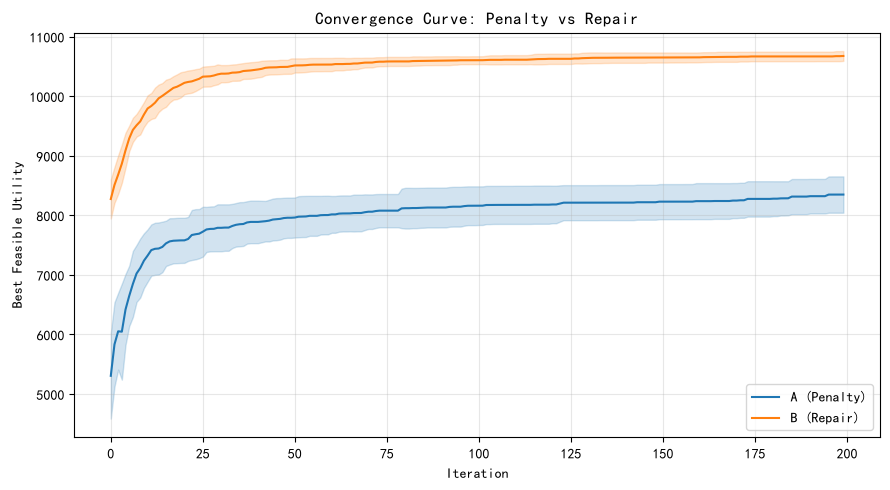

In [10]:
# Convergence curve
def plot_convergence(histA, histB, labelA="A (Penalty)", labelB="B (Repair)"):
    plt.figure(figsize=(9, 5))
    for hist, lab, color in [(histA, labelA, 'C0'), (histB, labelB, 'C1')]:
        mean = np.nanmean(hist, axis=0)
        std  = np.nanstd(hist, axis=0)
        x = np.arange(len(mean))
        plt.plot(x, mean, label=lab, color=color)
        plt.fill_between(x, mean - std, mean + std, color=color, alpha=0.2)
    plt.xlabel("Iteration")
    plt.ylabel("Best Feasible Utility")
    plt.title("Convergence Curve: Penalty vs Repair")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_convergence(resA_hists, resB_hists)

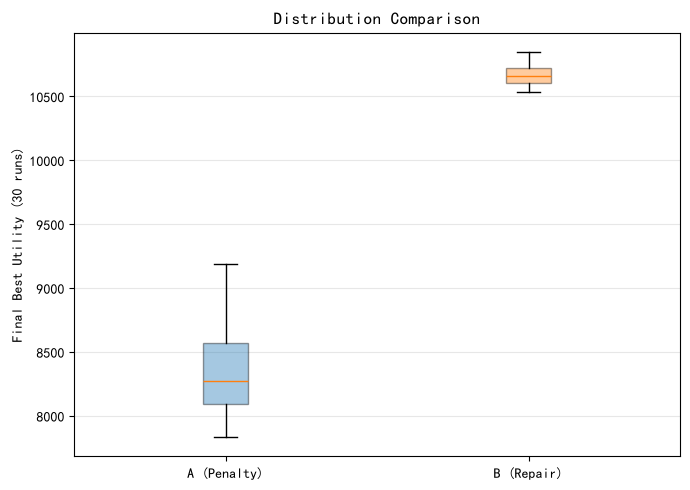

In [12]:
# Box plots
plt.figure(figsize=(7, 5))
bp = plt.boxplot([resA_fits, resB_fits], 
                 tick_labels=["A (Penalty)", "B (Repair)"],  # <--- 这里改成了 tick_labels
                 patch_artist=True)

for patch, color in zip(bp['boxes'], ['C0', 'C1']):
    patch.set_facecolor(color)
    patch.set_alpha(0.4)
    
plt.ylabel("Final Best Utility (30 runs)")
plt.title("Distribution Comparison")
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

## 10. Mann-Whitney U test

In [13]:
stat, p = mannwhitneyu(resA_fits, resB_fits, alternative='two-sided')
alpha = 0.05
print(f"Mann-Whitney U statistic = {stat:.1f}")
print(f"p-value = {p:.4g}")
if p < alpha:
    print(f"-> Reject the null hypothesis at alpha={alpha}: "
          f"the final fitness distributions of A and B are significantly different")
else:
    print(f"-> Fail to reject the null hypothesis at alpha={alpha}: "
          f"no significant difference between A and B")

# Mean and median differences
print(f"Mean   diff (B - A) = {resB_fits.mean() - resA_fits.mean():+.2f}")
print(f"Median diff (B - A) = {np.median(resB_fits) - np.median(resA_fits):+.2f}")

Mann-Whitney U statistic = 0.0
p-value = 3.018e-11
-> Reject the null hypothesis at alpha=0.05: the final fitness distributions of A and B are significantly different
Mean   diff (B - A) = +2326.53
Median diff (B - A) = +2384.00
